# A variational autoencoder for digit images

How does a probabilistic latent space trade reconstruction against regularization?

I train an eight-dimensional Gaussian encoder with reparameterized samples. Reconstructions use the posterior mean for deterministic evaluation, while generated images sample the standard normal prior.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import torch
from torch.utils.data import TensorDataset

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from deep_projects.training import (
    DataSplit,
    Trainer,
    TrainConfig,
    digits_data,
    image_grid,
    plot_history,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "09_variational_autoencoder"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Probabilistic encoder

The encoder predicts $\mu(x)$ and $\log\sigma^2(x)$. Sampling uses $z=\mu+\sigma\epsilon$, which lets gradients pass through the encoder. The objective sums reconstruction errors per image and adds $\beta D_{KL}(q(z|x)\|N(0,I))$; beta is fixed at 0.05 for this experiment.

class VariationalAutoencoder(nn.Module):
    def __init__(self, latent=8):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(64, 64), nn.ReLU())
        self.mean = nn.Linear(64, latent)
        self.log_variance = nn.Linear(64, latent)
        self.decoder = nn.Sequential(nn.Linear(latent, 64), nn.ReLU(), nn.Linear(64, 64), nn.Sigmoid())

    def encode(self, images):
        hidden = self.encoder(images.flatten(1))
        return self.mean(hidden), self.log_variance(hidden)

    def forward(self, images):
        mean, log_variance = self.encode(images)
        latent = mean + torch.exp(0.5 * log_variance) * torch.randn_like(mean) if self.training else mean
        return self.decoder(latent).view_as(images), mean, log_variance

class ELBOLoss(nn.Module):
    def __init__(self, beta=0.05):
        super().__init__()
        self.beta = beta

    def forward(self, output, target):
        reconstructed, mean, log_variance = output
        reconstruction = (reco

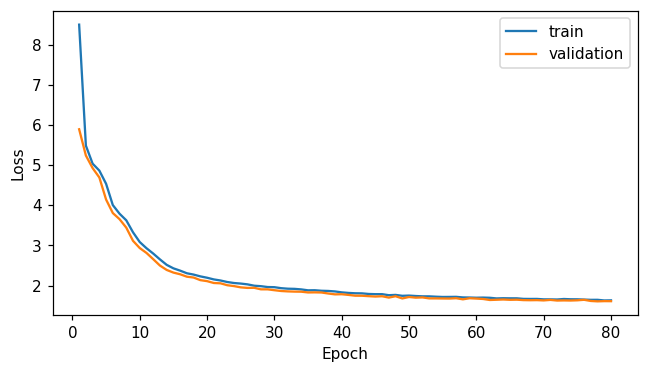

In [5]:
from deep_projects.models import VariationalAutoencoder, ELBOLoss

data = digits_data(8)
reconstruction_data = DataSplit(
    *(
        TensorDataset(dataset.tensors[0], dataset.tensors[0])
        for dataset in [data.train, data.validation, data.test]
    )
)
train_loader, validation_loader, test_loader = reconstruction_data.loaders()
print(inspect.getsource(VariationalAutoencoder))
print(inspect.getsource(ELBOLoss))
model = VariationalAutoencoder(latent=8)
history = Trainer(model, ELBOLoss(beta=0.05), TrainConfig(epochs=EPOCHS * 2)).fit(
    train_loader, validation_loader
)
plot_history(history, output / "loss.png")

## Reconstruction and KL

The analytic diagonal-Gaussian KL can be checked against PyTorch distributions. It is zero for the standard normal posterior. I separate per-image reconstruction sum from KL, because a single combined objective obscures their relative scales.

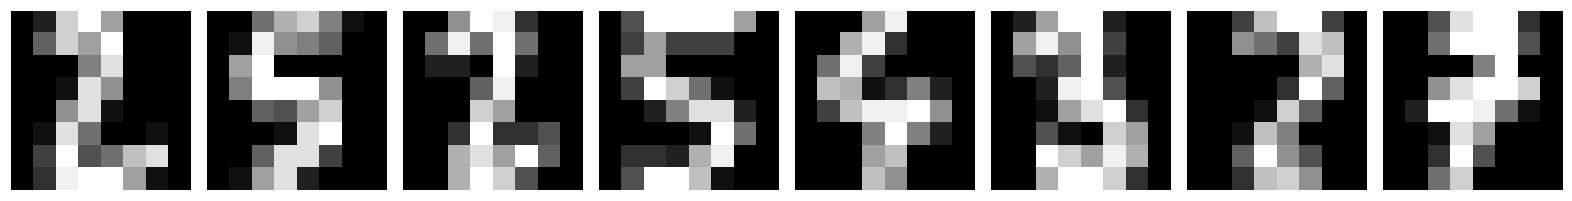

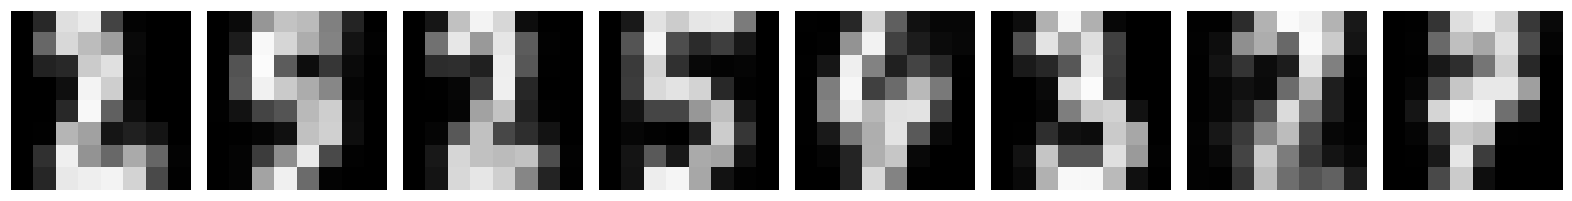

{'reconstruction_sum': 0.9829508662223816, 'kl': 11.496587753295898}


In [7]:
model.eval()
images = reconstruction_data.test.tensors[0]
with torch.inference_mode():
    reconstructed, mean, log_variance = model(images)
reconstruction_sum = float((reconstructed - images).square().flatten(1).sum(-1).mean())
kl = float(
    (-0.5 * (1 + log_variance - mean.square() - log_variance.exp()).sum(-1)).mean()
)
posterior = torch.distributions.Normal(mean, torch.exp(0.5 * log_variance))
prior = torch.distributions.Normal(torch.zeros_like(mean), torch.ones_like(mean))
reference_kl = torch.distributions.kl_divergence(posterior, prior).sum(-1).mean()
assert abs(float(reference_kl) - kl) < 1e-5
image_grid(images[:8], output / "original.png")
image_grid(reconstructed[:8], output / "reconstructed.png")
print({"reconstruction_sum": reconstruction_sum, "kl": kl})

## Prior samples and latent interpolation

Prior samples test whether the learned decoder can handle standard-normal codes. Interpolation between two posterior means shows a decoder path, but does not prove that every intermediate image is likely under the data distribution.

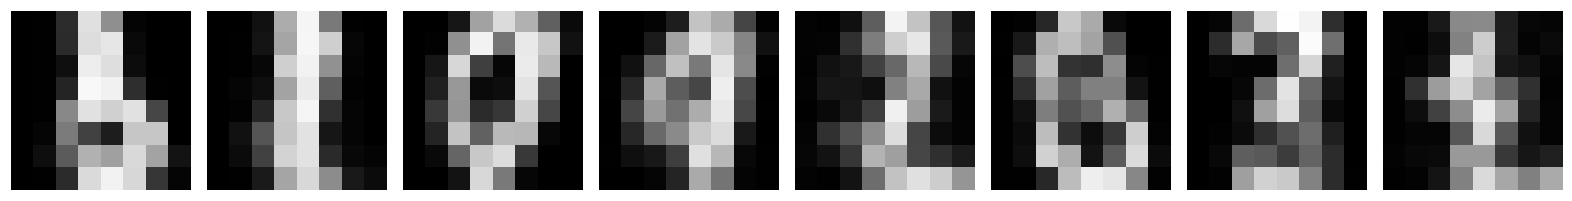

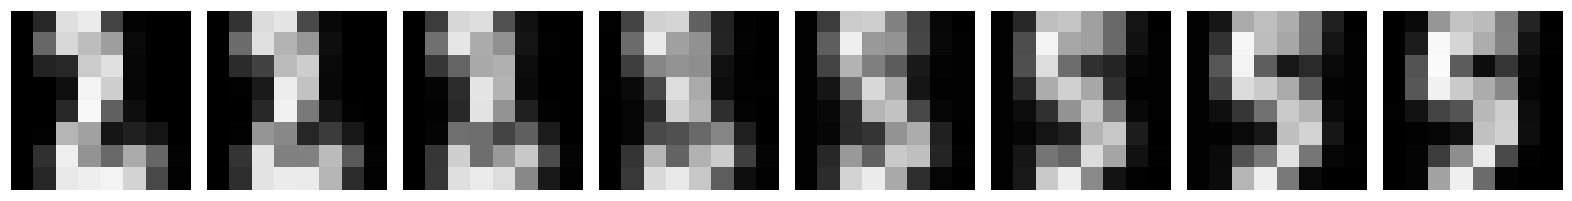

In [9]:
with torch.inference_mode():
    generated = model.decoder(torch.randn(8, 8)).reshape(8, 1, 8, 8)
    weights = torch.linspace(0, 1, 8)[:, None]
    path = (1 - weights) * mean[0] + weights * mean[1]
    interpolated = model.decoder(path).reshape(8, 1, 8, 8)
image_grid(generated, output / "prior_samples.png")
image_grid(interpolated, output / "interpolation.png")
results = {
    "test_reconstruction_sum": reconstruction_sum,
    "test_kl": kl,
    "beta": 0.05,
    "latent_dimensions": 8,
    "deterministic_test_reconstruction": True,
}

## Reading the result

A low KL may indicate that the encoder uses little image-specific information. The reconstruction term's scale depends on its sum over 64 pixels. These quantities need to be reported with beta before comparing another VAE implementation.

In [11]:
result_path = root / "results" / "09_variational_autoencoder.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/09_variational_autoencoder.json


## Next experiment

Compare beta values using validation reconstruction and KL. Track the number of latent dimensions with appreciable posterior-mean variance, then inspect prior samples for each setting.

## Sources

[Practical DL, HSE, YSDA and Skoltech](https://github.com/yandexdataschool/Practical_DL/tree/fall25). [Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.